<div style="background:rgba(128,128,128,0.05);border:1px solid rgba(128,128,128,0.26);color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));border-radius:12px;padding:28px 30px;"><div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Qiskit Fall Fest CT 2026 &nbsp;·&nbsp; qBraid challenge &nbsp;·&nbsp; Resource 2 of 3</span></div><div style="margin:0 0 14px 0;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:12px;letter-spacing:1px;color:rgba(128,128,128,0.98);white-space:nowrap;"><svg width="12" height="12" viewBox="0 0 24 24" fill="none" stroke="rgba(128,128,128,0.98)" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>about 40 minutes end to end</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:38px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">Run your circuits on <span style="color:#0E9488;">qBraid</span></div><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">You can already build a circuit in Qiskit and simulate it on your laptop. A laptop runs out of memory near 30 qubits, though, and it has no quantum hardware attached. The <b>qBraid SDK</b> is a Python package that sends the same circuit to cloud simulators and real quantum computers. It then hands the results back.</p><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">In this notebook you send a Qiskit circuit to AWS SV1 and read the answer. The path:</p><ol style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 9px 0;"><b style="font-weight:600;">What qBraid gives you.</b> <span style="color:rgba(128,128,128,0.98);">The parts of the platform this challenge uses.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Connecting to a device.</b> <span style="color:rgba(128,128,128,0.98);">One provider object, then one device by its id.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Sending a Qiskit circuit.</b> <span style="color:rgba(128,128,128,0.98);">A circuit with a known answer, run on SV1, with the bit order pinned down.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Following a job.</b> <span style="color:rgba(128,128,128,0.98);">Job ids, status, results, and how to send several circuits together.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Moving between frameworks.</b> <span style="color:rgba(128,128,128,0.98);">The qBraid transpiler turns one circuit into another framework's format.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Keeping costs down.</b> <span style="color:rgba(128,128,128,0.98);">What a job costs, and the habits that save credits.</span></li></ol><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">The next resource, <code>03_qaoa_maxcut_with_qbraid.ipynb</code>, uses all of this to run a real optimization algorithm.</p></div>

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Before you start</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

The two cells below install anything that is missing and set up plotting. Run both and carry on. Other helpers arrive as the notebook reaches them.

In [1]:
import importlib.util
import subprocess
import sys

# install only what is missing; upgrading an already-imported package can break it
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc",
          "braket": "amazon-braket-sdk"}
missing = [spec for mod, spec in NEEDED.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [2]:
import io

import matplotlib.pyplot as plt
from IPython.display import Image, display

SEED = 7
GREY, VIOLET, TEAL, AMBER = "#8A8A8A", "#8B5CF6", "#0E9488", "#C2772A"
plt.rcParams.update({"figure.facecolor": "none", "axes.facecolor": "none",
                     "savefig.facecolor": "none", "savefig.edgecolor": "none",
                     "figure.dpi": 110, "axes.edgecolor": GREY,
                     "text.color": GREY, "axes.labelcolor": GREY,
                     "xtick.color": GREY, "ytick.color": GREY})


def show(fig):
    """Show a figure with a transparent background, whatever the page theme."""
    # sending the PNG ourselves stops the notebook painting a dark box behind it
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", transparent=True, bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Section 1 · What qBraid gives you</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What do you get with a <span style="color:#0E9488;">qBraid account</span>?</div>

Your qBraid account gives you four things this challenge relies on:

- **qBraid Lab**, a JupyterLab environment in the browser with the packages already installed.
- **Credits**, the currency every job is paid in. One US dollar buys 100 credits.
- **Devices**, the simulators and quantum computers you can send jobs to, from many vendors.
- **The [quantum jobs page](https://account.qbraid.com/quantum-jobs)**, a list of every job you submit, with its status and cost.

This notebook uses one device: **SV1**, the state-vector simulator that Amazon Braket runs. A state-vector simulator stores every amplitude of the state exactly. It then samples outcomes from those amplitudes, the same way a measurement would. These numbers come from qBraid's device listing and from real jobs on the platform:

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="display:flex;gap:26px;flex-wrap:wrap;"><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#0E9488;line-height:1.1;">34</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">qubits on SV1</div></div><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#0E9488;line-height:1.1;">50,000</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">shots per job, at most</div></div><div style="flex:1;min-width:120px;border-left:2px solid #C2772A;padding-left:14px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:34px;color:#C2772A;line-height:1.1;">0.375</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:#C2772A;margin-top:6px;">credits per short job</div></div></div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;color:rgba(128,128,128,0.98);line-height:1.6;margin-top:16px;padding-top:12px;border-top:1px solid rgba(128,128,128,0.26);">A short SV1 job costs 0.375 credits, under one US cent. qBraid lists SV1 at 7.5 credits per minute of simulation.</div></div>

In qBraid Lab your credentials are already set up. On your own machine, set the `QBRAID_API_KEY` environment variable or run `qbraid configure` once. The [API key guide](https://docs.qbraid.com/v2/account/api-keys) shows where to find your key.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Section 2 · Connecting to a device</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do you <span style="color:#0E9488;">reach a device</span> from Python?</div>

Every connection starts with a **provider**. A provider is an object that knows your account and lists the devices you can use. `QbraidProvider` is qBraid's provider. You then ask it for one device by its **device id**, a string of the form `vendor:provider:type:name`.

SV1's id is `aws:aws:sim:sv1`. The cell below asks for it. If the notebook cannot reach qBraid, the cell says so and sets `sv1` to `None`. Later cells check that value, so the notebook still runs from top to bottom.

In [3]:
from qbraid.exceptions import QbraidError
from qbraid.runtime import QbraidProvider

provider = QbraidProvider()
try:
    sv1 = provider.get_device("aws:aws:sim:sv1")
except QbraidError:
    sv1 = None
    print("No qBraid credentials here, so this cell cannot reach qBraid. "
          "In qBraid Lab it connects to SV1 and prints its status.")
else:
    print(sv1.id, "|", sv1.status().name, "|", sv1.num_qubits, "qubits")

No qBraid credentials here, so this cell cannot reach qBraid. In qBraid Lab it connects to SV1 and prints its status.


The provider can also list every device your account can see. Each device reports a **status**: `ONLINE` means it accepts jobs now. Run the cell and look for SV1 and a few real quantum computers.

In [4]:
if sv1 is None:
    print("Skipped: no connection to qBraid. In qBraid Lab this lists every device.")
else:
    for device in sorted(provider.get_devices(), key=lambda d: d.id):
        print(f"{device.id:<45} {device.status().name}")

Skipped: no connection to qBraid. In qBraid Lab this lists every device.


<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Section 3 · Sending a Qiskit circuit</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>10 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do you <span style="color:#0E9488;">run a Qiskit circuit</span> on SV1?</div>

Start with a circuit whose answer you know, so you can check the result. The circuit below has three qubits:

- an `X` gate flips qubit 0 to 1 every time,
- qubit 1 stays at 0, and
- a Hadamard gate puts qubit 2 in an equal superposition of 0 and 1.

Qiskit writes a result as a **bitstring** with qubit 0 on the right. So the two possible results are `001` and `101`. Predict the split before you run it.

The `CIRCUIT` style below draws circuits on a transparent background, so they read on a light or a dark page.

In [5]:
CIRCUIT = {"backgroundcolor": "#00000000", "linecolor": GREY,
           "textcolor": GREY, "subtextcolor": GREY, "gatetextcolor": "#FFFFFF",
           "displaycolor": {"h": (VIOLET, "#FFFFFF"), "x": (TEAL, "#FFFFFF"),
                            "ry": (VIOLET, "#FFFFFF"), "rx": (TEAL, "#FFFFFF"),
                            "rz": (AMBER, "#FFFFFF"), "rzz": (AMBER, "#FFFFFF"),
                            "cx": (TEAL, "#FFFFFF"), "cz": (AMBER, "#FFFFFF")}}

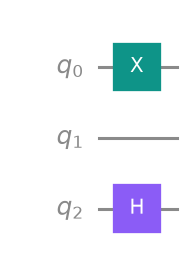

In [6]:
from qiskit import QuantumCircuit

known = QuantumCircuit(3)
known.x(0)
known.h(2)
show(known.draw("mpl", style=CIRCUIT))

Devices do not all agree on bit order. Qiskit puts qubit 0 on the right. Some services put qubit 0 on the left. Read a result in the wrong order and `001` turns into `100`, a different answer.

The helper below removes that risk. `run_on_sv1` adds one extra **marker qubit** set to 1. The marker is always the last qubit. Its position in each returned bitstring shows which end holds the last qubit. The helper then drops the marker and returns the counts in Qiskit order. It also **transpiles** the circuit. Here that means rewriting it in a small set of basic gates that every service accepts.

Without credentials, `run_on_sv1` runs the same circuit on the local Aer simulator and says so. Aer is Qiskit's simulator for your own machine.

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qbraid.exceptions import QbraidError
from qbraid.runtime import QbraidProvider

SV1 = "aws:aws:sim:sv1"


def strip_marker(raw):
    """Drop the marker bit and return keys in Qiskit order (last qubit first)."""
    left = all(key[0] == "1" for key in raw)
    right = all(key[-1] == "1" for key in raw)
    if left:
        return {key[1:]: n for key, n in raw.items()}
    if right:
        return {key[:-1][::-1]: n for key, n in raw.items()}
    raise ValueError("marker bit not found; were the counts measured with run_on_sv1?")


def run_on_sv1(circuit, shots=1000):
    """Run a measurement-free circuit on AWS SV1 through qBraid; return counts."""
    n = circuit.num_qubits
    qc = QuantumCircuit(n + 1)
    qc.compose(circuit, range(n), inplace=True)
    qc.x(n)  # marker qubit, always 1: it shows which end of each key is the last qubit
    qc.measure_all()
    qc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
    try:
        device = QbraidProvider().get_device(SV1)
    except QbraidError:
        print("No qBraid credentials here, so this ran on the local simulator. "
              "In qBraid Lab this cell submits to SV1.")
        raw = AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()
    else:
        job = device.run(qc, shots=shots)
        print(f"submitted job {job.id} to {SV1}")
        print("follow it at https://account.qbraid.com/quantum-jobs")
        raw = job.result().data.get_counts()
    return strip_marker(raw)

`plot_counts` turns a counts dictionary into a bar chart of the fraction of shots per bitstring. Run the circuit and compare the chart with your prediction.

No qBraid credentials here, so this ran on the local simulator. In qBraid Lab this cell submits to SV1.
{'101': 2040, '001': 1960}


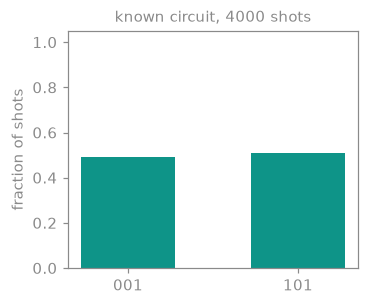

In [8]:
def plot_counts(counts, title=""):
    shots = sum(counts.values())
    labels = sorted(counts)
    fig, ax = plt.subplots(figsize=(1.6 + 0.9 * len(labels), 2.8))
    ax.bar(labels, [counts[k] / shots for k in labels], color=TEAL, width=0.55)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("fraction of shots")
    ax.set_title(title, fontsize=10)
    show(fig)


counts = run_on_sv1(known, shots=4000)
print(counts)
plot_counts(counts, "known circuit, 4000 shots")

About half the shots return `001` and half return `101`. The split is not exactly 2000 and 2000, because a finite number of shots carries sampling noise. With 4000 shots the typical gap from 2000 is about 32.

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">The maths &nbsp;&middot;&nbsp; why the gap is about 32<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

Each shot lands on `101` with probability $p = 1/2$. Over $n$ shots the count of `101` has standard deviation $\sqrt{n\,p\,(1-p)}$.

With $n = 4000$ that is $\sqrt{1000} \approx 31.6$. Four times the shots halves the relative noise, because the noise grows as $\sqrt{n}$ while the count grows as $n$.

</details>

The helper hides the submission lines. Without it, the direct path is four lines. You build the provider, get the device, call `run`, then read the counts:

```python
from qiskit import transpile

qc = known.copy()
qc.measure_all()
job = sv1.run(transpile(qc, basis_gates=["rz", "sx", "x", "cx"]), shots=1000)
counts = job.result().data.get_counts()
```

This direct path skips the marker. Check the bit order of your device before you trust a result.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Section 4 · Following a job</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What happens to a job <span style="color:#0E9488;">after you submit it</span>?</div>

A **job** is one request to run a circuit on a device. Every job gets a **job id**, a unique string that starts with the device id. The job then moves through a series of statuses:

- `INITIALIZING` and `QUEUED` while it waits for the device,
- `RUNNING` while the device executes it, and
- `COMPLETED`, `FAILED` or `CANCELLED` once it is over.

The same job appears on the [quantum jobs page](https://account.qbraid.com/quantum-jobs) with its cost. That page is the record your team can point to after the hackathon. The cell below submits one job directly and follows it.

In [9]:
if sv1 is None:
    print("Skipped: no connection to qBraid. In qBraid Lab this submits one "
          "SV1 job for 0.375 credits and prints its id, status and counts.")
else:
    qc = known.copy()
    qc.measure_all()
    job = sv1.run(transpile(qc, basis_gates=["rz", "sx", "x", "cx"]), shots=100)
    print("job id:", job.id)
    print("status:", job.status().name)
    result = job.result()  # waits until the job is over
    print("status:", job.status().name)
    print("counts:", result.data.get_counts())

Skipped: no connection to qBraid. In qBraid Lab this submits one SV1 job for 0.375 credits and prints its id, status and counts.


Optimization algorithms send many circuits, one per guess. Pass a list of circuits to `run` and you get back a list of jobs. SV1 does not accept a batch as one job, so each circuit becomes its own job at 0.375 credits.

A `GroupJobSession` keeps related jobs together. Every job you submit inside the `with` block is tagged with the group. You can then wait for the whole group at once:

In [10]:
from qbraid.runtime import GroupJobSession

if sv1 is None:
    print("Skipped: no connection to qBraid. In qBraid Lab this submits two "
          "SV1 jobs as one group.")
else:
    batch = []
    for angle in (0.0, 1.0):
        qc = QuantumCircuit(1)
        qc.ry(angle, 0)
        qc.measure_all()
        batch.append(transpile(qc, basis_gates=["rz", "sx", "x", "cx"]))
    with GroupJobSession(name="ry-sweep", client=provider.client) as group:
        jobs = sv1.run(batch, shots=200)
    for job_id, result in group.results(timeout=300).results.items():
        print(job_id, result.data.get_counts())

Skipped: no connection to qBraid. In qBraid Lab this submits two SV1 jobs as one group.


<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Section 5 · Moving between frameworks</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do you move a circuit to <span style="color:#0E9488;">another framework</span>?</div>

Quantum programs come in many formats. Qiskit has its own circuit class. Amazon Braket has another. **OpenQASM 3** is a plain-text language that many services read. The **qBraid transpiler** converts a circuit from one format to another with one call, `qbraid.transpile(circuit, target)`.

That is why qBraid accepts circuits from any supported framework. Your team can write in the framework it knows, and qBraid converts the circuit for the device. The cell below converts the known circuit to Braket and to OpenQASM 3.

In [11]:
import qbraid

braket_circuit = qbraid.transpile(known, "braket")
print(braket_circuit)
print(qbraid.transpile(known, "qasm3"))

T  : │  0  │
      ┌───┐ 
q0 : ─┤ X ├─
      └───┘ 
      ┌───┐ 
q2 : ─┤ H ├─
      └───┘ 
T  : │  0  │
OPENQASM 3.0;
include "stdgates.inc";
qubit[3] q;
x q[0];
h q[2];



A conversion is only useful if it keeps the circuit's meaning. `circuits_allclose` checks that two circuits apply the same operation. It compares their matrices, ignoring a global phase.

Look at the Braket printout again: qubit 1 is missing. Braket keeps only the qubits that a gate touches, so its circuit has two qubits. `index_contig=True` closes that gap before the comparison.

In [12]:
from qbraid.interface import circuits_allclose

print("same operation:", circuits_allclose(known, braket_circuit, index_contig=True))

same operation: True


The targets you can reach depend on the packages installed. This notebook installs Qiskit and Braket, so three targets work here:

- `braket`, an Amazon Braket circuit,
- `qasm2`, OpenQASM 2 text, and
- `qasm3`, OpenQASM 3 text.

The [transpiler guide](https://docs.qbraid.com/v2/sdk/user-guide/transpiler) lists the other frameworks.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Section 6 · Keeping costs down</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#0E9488;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#0E9488" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do you keep your <span style="color:#0E9488;">credit spend</span> low?</div>

Simulators and quantum computers charge in different ways. qBraid lists two pricing parts for each device:

- a **per-task** charge, paid once per job, and
- a **per-shot** charge, paid for every repetition of the circuit.

SV1 charges by simulation time instead. A short job costs 0.375 credits, whatever the shot count. A quantum computer such as IQM Garnet charges 30 credits per task plus 0.145 credits per shot. The chart compares the two as the shot count grows.

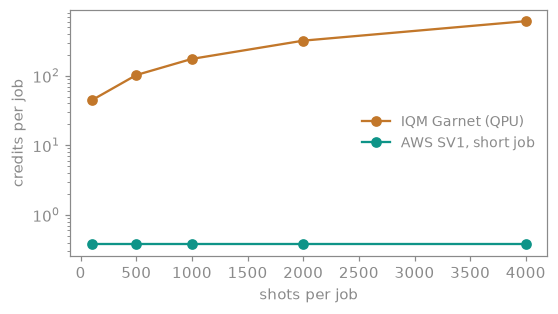

Garnet at 1000 shots: 175.0 credits


In [13]:
shots = [100, 500, 1000, 2000, 4000]
garnet = [30 + 0.145 * s for s in shots]
sv1_cost = [0.375] * len(shots)

fig, ax = plt.subplots(figsize=(5.6, 2.9))
ax.plot(shots, garnet, marker="o", color=AMBER, label="IQM Garnet (QPU)")
ax.plot(shots, sv1_cost, marker="o", color=TEAL, label="AWS SV1, short job")
ax.set_yscale("log")
ax.set_xlabel("shots per job")
ax.set_ylabel("credits per job")
ax.legend(frameon=False, fontsize=9)
show(fig)
print("Garnet at 1000 shots:", 30 + 0.145 * 1000, "credits")

At 1000 shots one Garnet job costs 175 credits, about 470 times an SV1 job. An optimization loop that sends 200 circuits makes the gap matter. Three habits keep the cost down:

- **Debug on Aer first.** It is free and runs on your own machine. Move to SV1 only once the code works.
- **Use the fewest shots that answer the question.** Sampling noise falls only as the square root of the shot count.
- **Check the price before you run.** `device.metadata()` and the device page list each device's pricing.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #0E9488;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#0E9488;margin-bottom:7px;">Credits for the hackathon</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Your team's credits are shared. Every job lands on the quantum jobs page with its cost. Agree on a budget before you send a loop of circuits.</div></div>

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#0E9488;">Recap</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What did you learn?</div>

- **A provider** lists devices. `QbraidProvider().get_device(id)` returns one device.
- **A device id** names the device. SV1 is `aws:aws:sim:sv1`.
- **A job** has an id and a status, and `job.result().data.get_counts()` returns its counts.
- **Bit order** differs between services. A marker qubit pins it down.
- **The transpiler** converts a circuit between frameworks with `qbraid.transpile`.
- **Cost** depends on the device. Debug on Aer, then use SV1, then hardware.

Next, open `03_qaoa_maxcut_with_qbraid.ipynb`. It builds the QAOA optimization algorithm for a graph problem and sends its circuits to SV1 with the same helper.